Задача 1

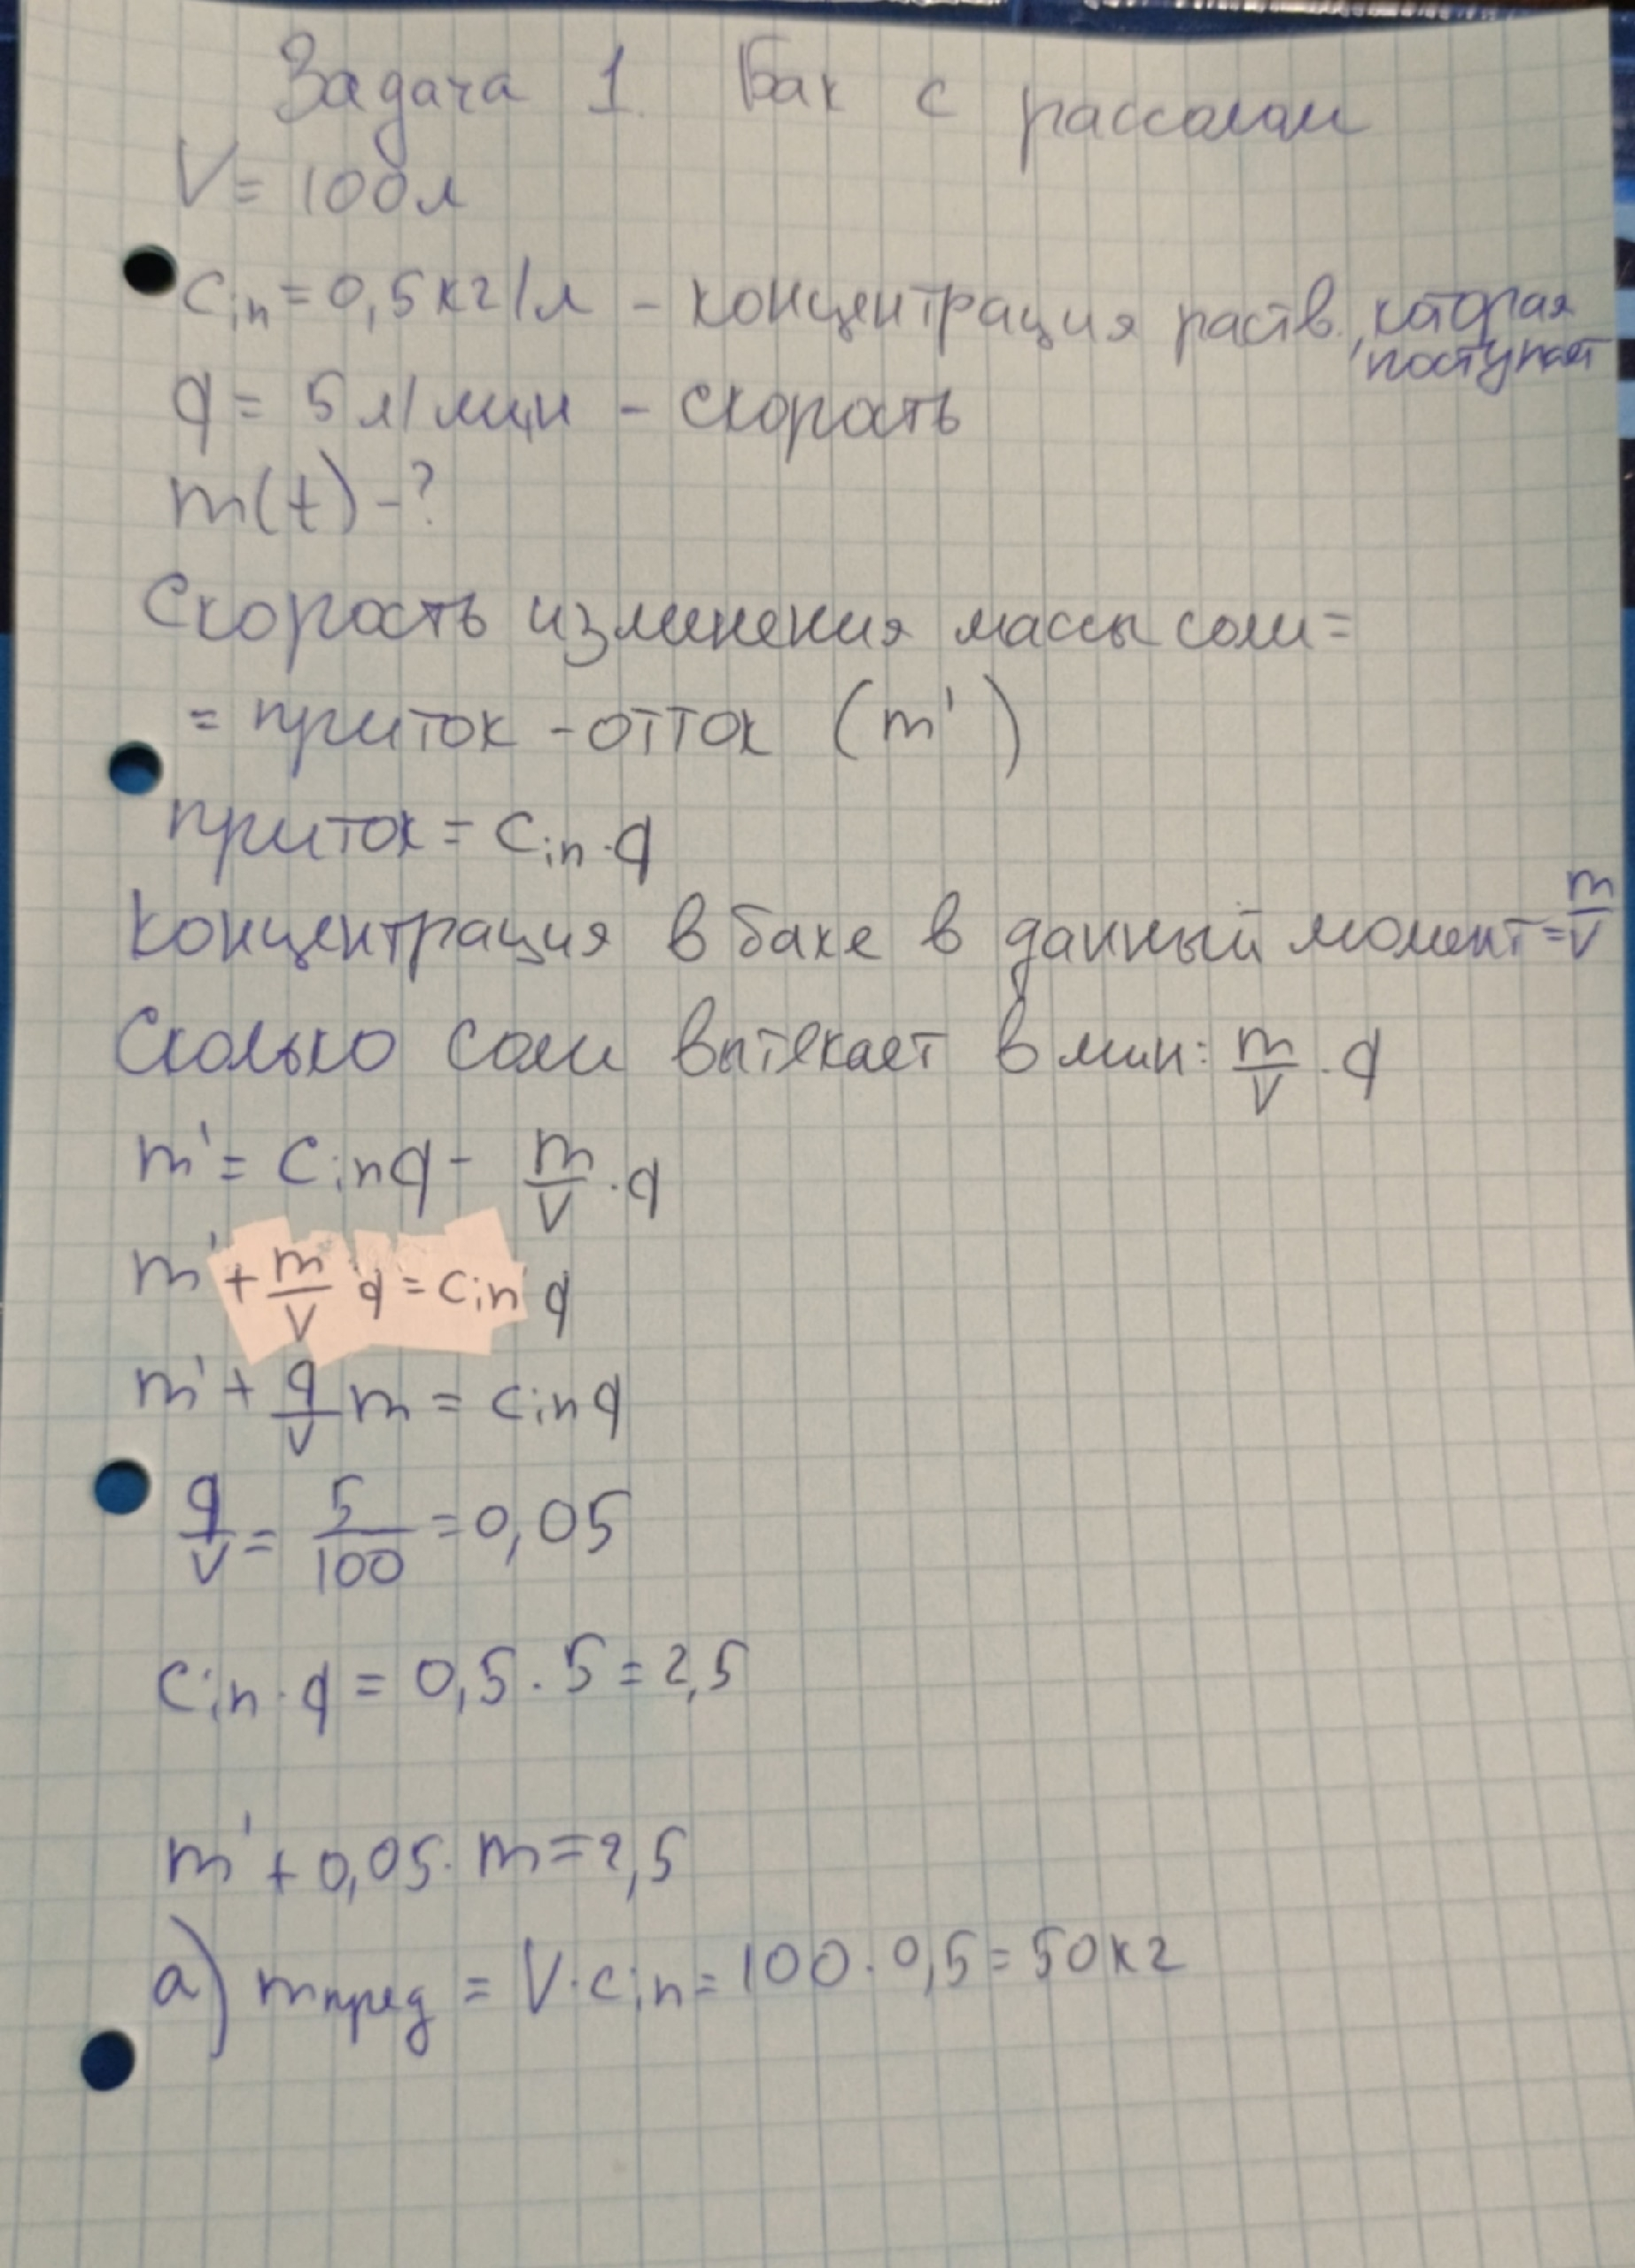

In [11]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

V = 100
c_in = 0.5
q = 5

In [12]:
t = sp.symbols('t', positive=True)
m = sp.Function('m')(t)

In [16]:
ode = sp.Eq(m.diff(t) + (q / V) * m, c_in * q) #задаем уравнение
ode

Eq(0.05*m(t) + Derivative(m(t), t), 2.5)

In [18]:
otv = sp.dsolve(ode, m, ics={m.subs(t, 0): 0}) #решение уравнение с начальным условием m(0)=0
otv

Eq(m(t), 50.0 - 50.0*exp(-0.05*t))

In [19]:
print("Решение уравнения:")
display(otv)

Решение уравнения:


Eq(m(t), 50.0 - 50.0*exp(-0.05*t))

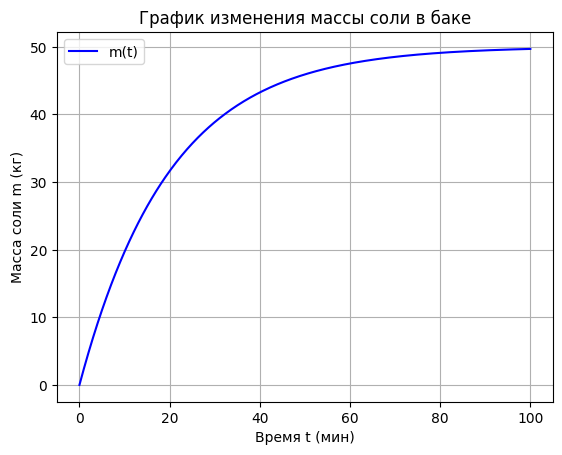

In [20]:
#строим график
m_func = sp.lambdify(t, otv.rhs, modules=['numpy'])
t_space = np.linspace(0, 100, 500)
m_space = m_func(t_space)

plt.figure()
plt.plot(t_space, m_space, label='m(t)', color='blue')
plt.title('График изменения массы соли в баке')
plt.xlabel('Время t (мин)')
plt.ylabel('Масса соли m (кг)')
plt.grid(True)
plt.legend()
plt.show()


Задача 2

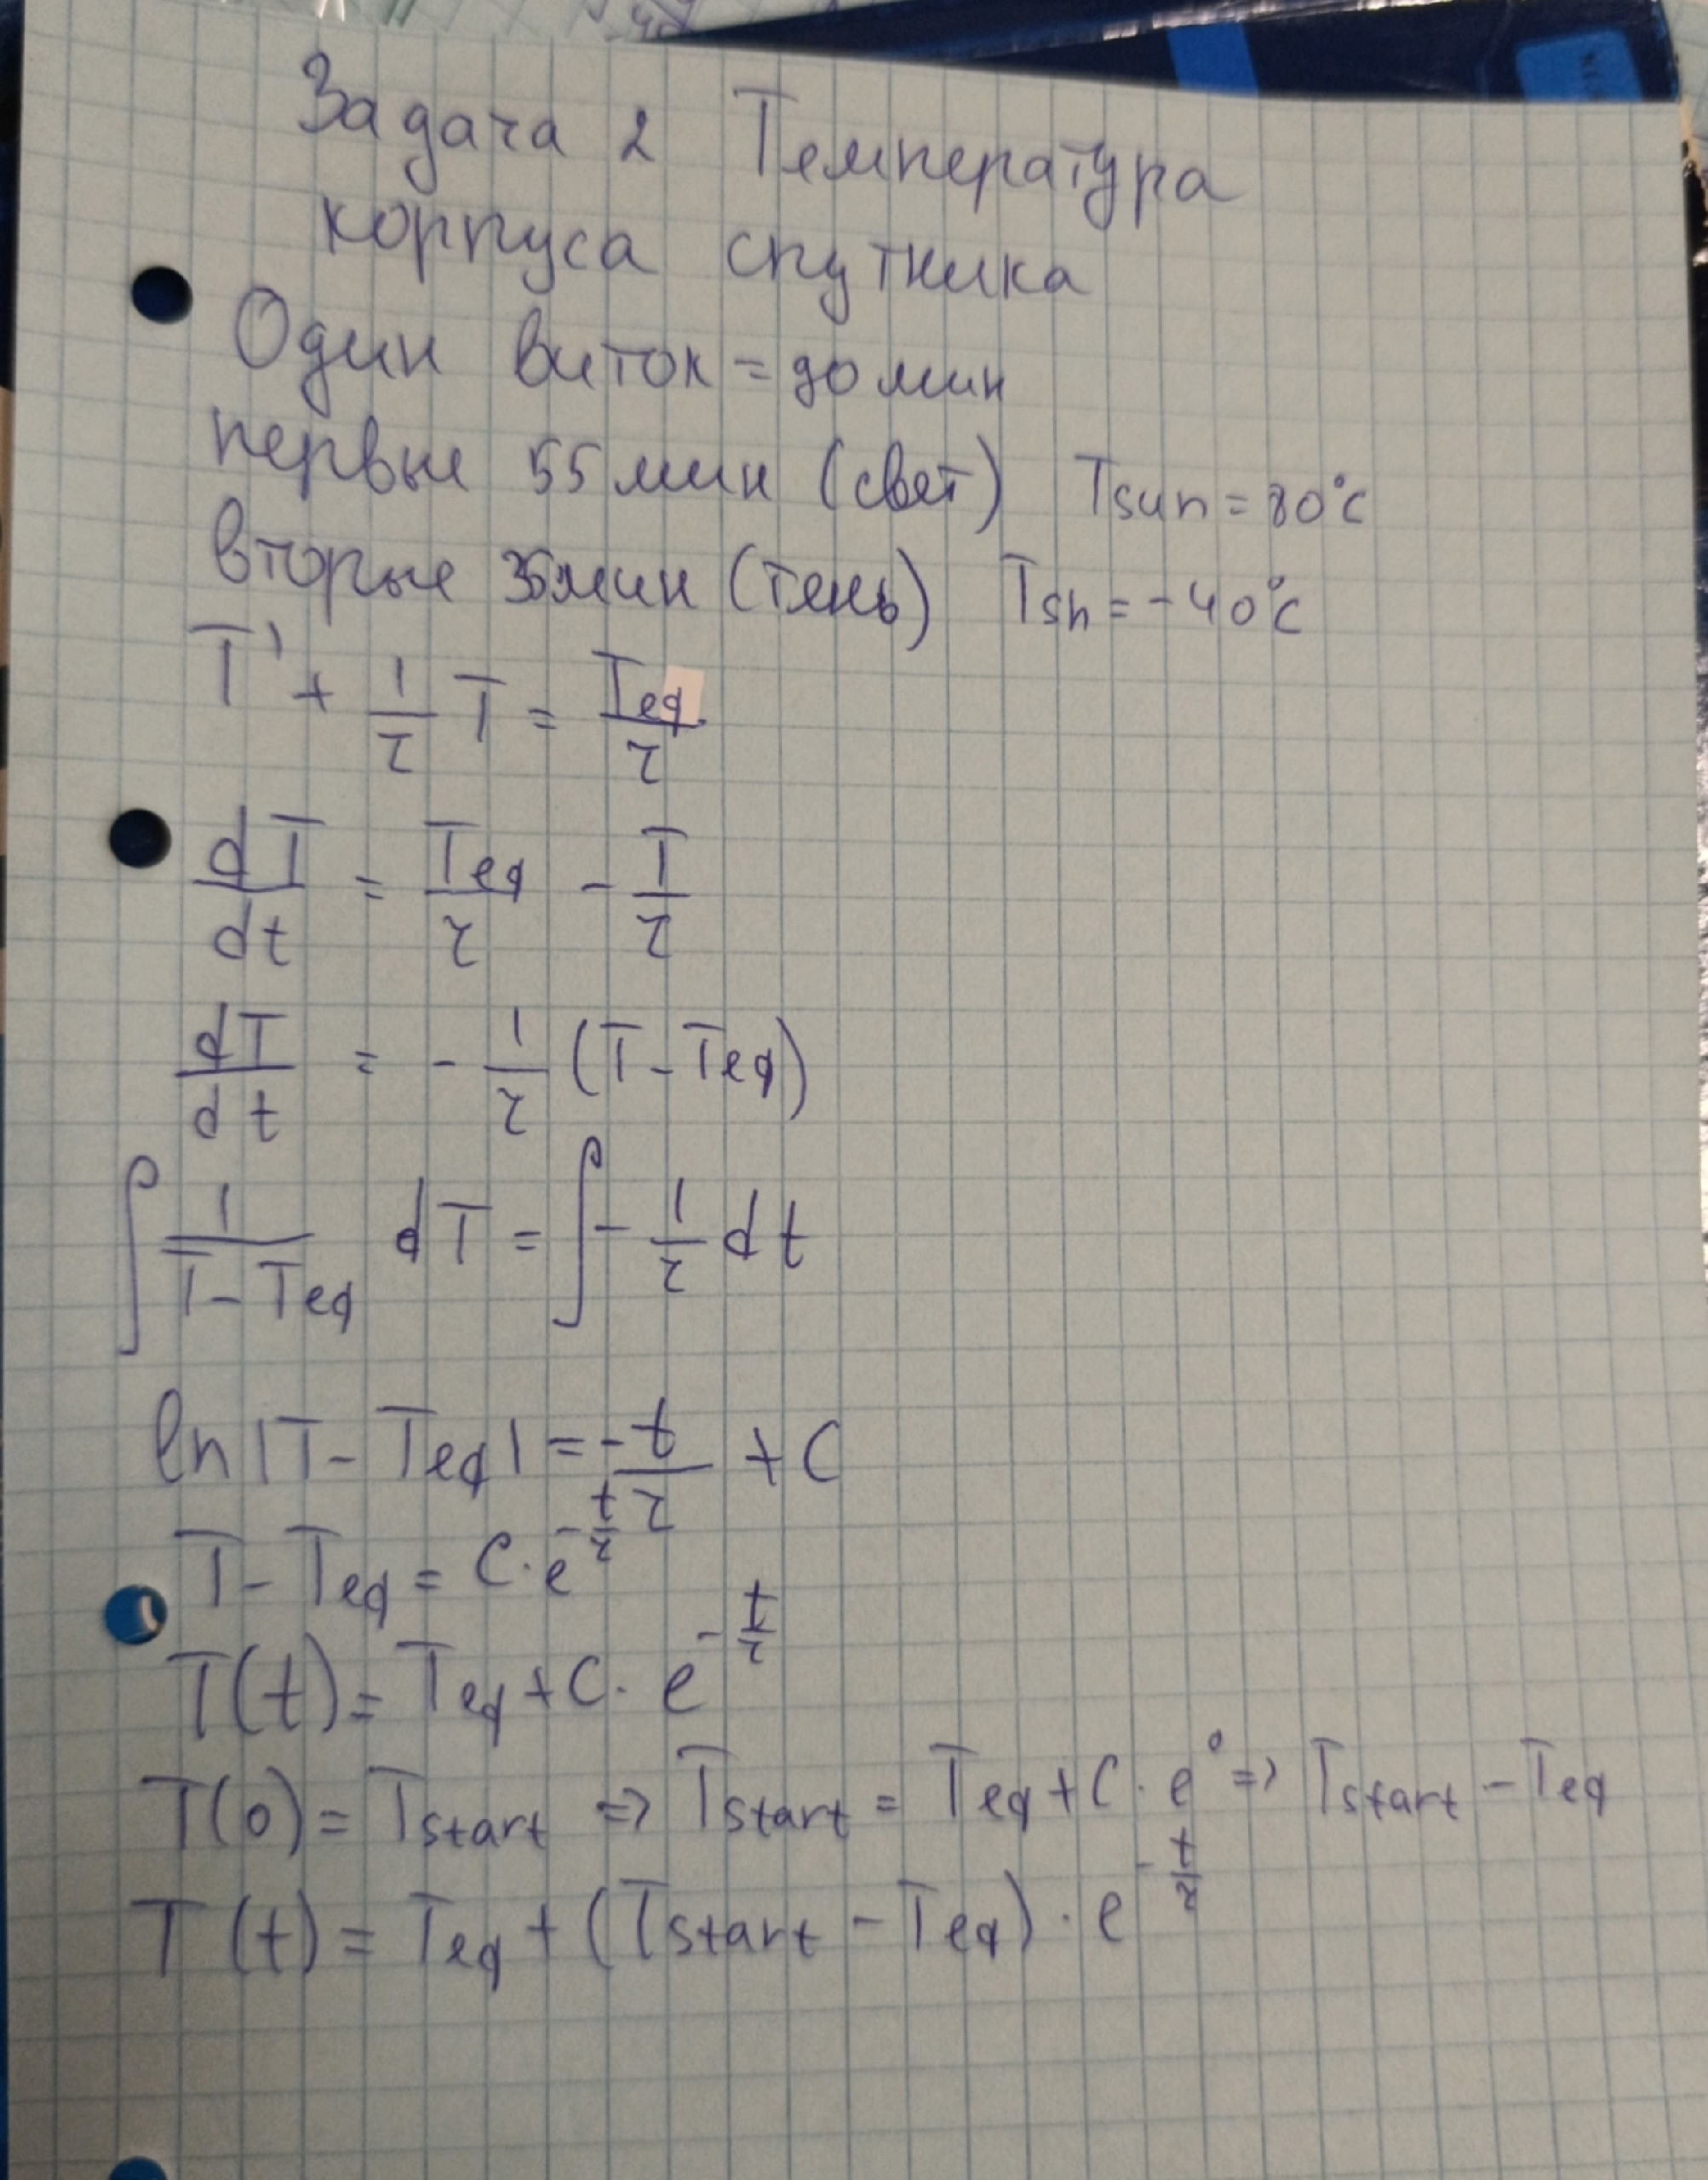

In [28]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

tau = 30       # Постоянная времени
T_sun = 80     # Температура на солнце
T_sh = -40     # Температура в тени
t_sun = 55     # Время на свету
t_sh = 35      # Время в тени
P = 90         # Период одного витка (55 + 35)
T0 = 20

In [29]:
t_sym = sp.symbols('t', positive=True)
T_func = sp.Function('T')(t_sym)
T_eq_sym, T_start_sym = sp.symbols('T_eq T_start')

ode = sp.Eq(T_func.diff(t_sym) + T_func / tau, T_eq_sym / tau)
ode

Eq(T(t)/30 + Derivative(T(t), t), T_eq/30)

In [30]:
sol = sp.dsolve(ode, T_func, ics={T_func.subs(t_sym, 0): T_start_sym})

print("Аналитическое решение")
display(sol)
calc_temp = sp.lambdify((t_sym, T_eq_sym, T_start_sym), sol.rhs, modules=['numpy'])

Аналитическое решение


Eq(T(t), T_eq + (-T_eq + T_start)*exp(-t/30))

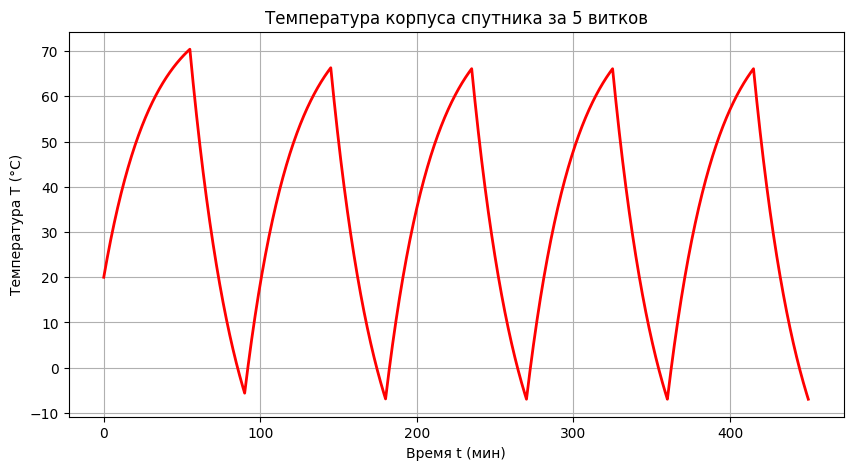

In [32]:

calc = sp.lambdify((t, T_eq, T_start), sol.rhs, modules=['numpy'])

# Виток 1
t1 = np.linspace(0, 55, 100);  T1 = calc(t1, 80, 20)     # Свет 1
t2 = np.linspace(0, 35, 100);  T2 = calc(t2, -40, T1[-1]) # Тень 1

# Виток 2
t3 = np.linspace(0, 55, 100);  T3 = calc(t3, 80, T2[-1])  # Свет 2
t4 = np.linspace(0, 35, 100);  T4 = calc(t4, -40, T3[-1]) # Тень 2

# Виток 3
t5 = np.linspace(0, 55, 100);  T5 = calc(t5, 80, T4[-1])  # Свет 3
t6 = np.linspace(0, 35, 100);  T6 = calc(t6, -40, T5[-1]) # Тень 3

# Виток 4
t7 = np.linspace(0, 55, 100);  T7 = calc(t7, 80, T6[-1])  # Свет 4
t8 = np.linspace(0, 35, 100);  T8 = calc(t8, -40, T7[-1]) # Тень 4

# Виток 5
t9 = np.linspace(0, 55, 100);  T9 = calc(t9, 80, T6[-1])  # Свет 5
t10 = np.linspace(0, 35, 100); T10 = calc(t10, -40, T9[-1]) # Тень 5

# 5. Склеиваем
t_all = np.concatenate([t1, t2+55, t3+90, t4+145, t5+180, t6+235, t7+270, t8+325, t9+360, t10+415])
T_all = np.concatenate([T1, T2, T3, T4, T5, T6, T7, T8, T9, T10])

plt.figure(figsize=(10, 5))
plt.plot(t_all, T_all, color='red', linewidth=2)
plt.title('Температура корпуса спутника за 5 витков')
plt.xlabel('Время t (мин)')
plt.ylabel('Температура T (°C)')
plt.grid(True)
plt.show()
